# Demo 2 — Character-level Spherical VAE for words

这个 notebook 演示第二个方案：**直接把单词字符矩阵输入 Spherical VAE**，像 MNIST 图像一样进行编码和重构。

\[
\text{word spelling}\rightarrow\text{character one-hot}\rightarrow\text{Spherical VAE}\rightarrow z\in S^{d-1}\rightarrow\text{reconstructed spelling}
\]

不使用 Word2Vec / GloVe / FastText。重点观察字符模型更容易学习：拼写、词缀、单复数、时态等 morphology，而不是完整语义。


In [1]:
import random
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from IPython.display import display

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("Device:", DEVICE)


Device: cuda


## 1. Character one-hot representation

使用 alphabet `a-z` + `PAD`，最大词长 \(L=20\)。因此每个单词表示为：

\[
X\in\{0,1\}^{20\times27}
\]

例如 `tiger`：前五行分别是 `t,i,g,e,r` 的 one-hot，后面全部 PAD。


In [2]:
ALPHABET = list("abcdefghijklmnopqrstuvwxyz")
PAD_TOKEN = "<PAD>"
VOCAB = [PAD_TOKEN] + ALPHABET
char_to_idx = {c:i for i,c in enumerate(VOCAB)}
idx_to_char = {i:c for c,i in char_to_idx.items()}
VOCAB_SIZE = len(VOCAB)
MAX_LEN = 20
print("VOCAB_SIZE:", VOCAB_SIZE, "MAX_LEN:", MAX_LEN)


VOCAB_SIZE: 27 MAX_LEN: 20


## 2. Small morphology-focused dataset

这个 demo 故意使用一个小而清晰的词表，用来验证字符模型是否能学到 morphology。


In [3]:
BASE_NOUNS = [
    "cat","dog","lion","tiger","bear","wolf","bird","horse","duck","goat",
    "cow","pig","car","train","plane","boat","book","chair","table","phone",
    "house","tree","flower","river","king","queen","boy","girl","friend","student",
]

BASE_VERBS = [
    "walk","play","talk","jump","look","cook","help","work","call","open",
    "clean","watch","visit","start","learn","move","turn","rain","smile","dance",
]

EXTRA_WORDS = [
    "category","cater","catalog","animal","feline","country","capital",
    "rome","italy","paris","france","happy","unhappy","kind","unkind",
]

def pluralize(word):
    if word.endswith("y"):
        return word[:-1] + "ies"
    if word.endswith(("s","x","z","ch","sh")):
        return word + "es"
    return word + "s"

def past_tense(word):
    if word.endswith("e"):
        return word + "d"
    return word + "ed"

def progressive(word):
    if word.endswith("e"):
        return word[:-1] + "ing"
    return word + "ing"

words=set(EXTRA_WORDS)
noun_pairs=[]; verb_past_pairs=[]; verb_ing_pairs=[]
for noun in BASE_NOUNS:
    p=pluralize(noun); words.update([noun,p]); noun_pairs.append((noun,p))
for verb in BASE_VERBS:
    pa=past_tense(verb); ing=progressive(verb)
    words.update([verb,pa,ing]); verb_past_pairs.append((verb,pa)); verb_ing_pairs.append((verb,ing))
words=sorted(w for w in words if len(w)<=MAX_LEN)
print("Number of words:", len(words))
display(pd.DataFrame({"word":words[:50]}))


Number of words: 135


,word
0,animal
1,bear
2,bears
3,bird
4,birds
5,boat
6,boats
7,boies
8,book
9,books


In [4]:
def encode_word_indices(word):
    ids=[char_to_idx[c] for c in word.lower() if c in char_to_idx][:MAX_LEN]
    ids += [char_to_idx[PAD_TOKEN]]*(MAX_LEN-len(ids))
    return np.asarray(ids,dtype=np.int64)

def indices_to_one_hot(indices):
    x=np.zeros((MAX_LEN,VOCAB_SIZE),dtype=np.float32)
    x[np.arange(MAX_LEN),indices]=1.0
    return x

def decode_indices(indices):
    return "".join(idx_to_char[int(i)] for i in indices if int(i)!=char_to_idx[PAD_TOKEN])

class WordCharacterDataset(Dataset):
    def __init__(self, words): self.words=list(words)
    def __len__(self): return len(self.words)
    def __getitem__(self,index):
        word=self.words[index]
        ids=encode_word_indices(word)
        return torch.tensor(indices_to_one_hot(ids),dtype=torch.float32), torch.tensor(ids,dtype=torch.long), word

dataset=WordCharacterDataset(words)
loader=DataLoader(dataset,batch_size=32,shuffle=True)
x,ids,w=dataset[words.index("tiger")]
print(w, x.shape, ids[:10].tolist())


tiger torch.Size([20, 27]) [20, 9, 7, 5, 18, 0, 0, 0, 0, 0]


## 3. Character Spherical VAE

Encoder 输入维度：\(20\times27=540\)。Latent 强制单位化，因此 \(z\in S^{d-1}\)。Decoder 对每个字符位置输出 categorical logits。


In [5]:
LATENT_DIM=16
HIDDEN_DIM=256
EPOCHS=250
LEARNING_RATE=1e-3
BETA_RIESZ=0.001
SAMPLE_ALPHA=0.10

def riesz_energy(points,s=1.0):
    if points.size(0)<2:
        return torch.zeros((),device=points.device)
    d=torch.cdist(points,points)
    mask=torch.triu(torch.ones_like(d,dtype=torch.bool),diagonal=1)
    valid=d[mask]
    return torch.mean(1.0/torch.clamp(valid,min=1e-4).pow(s))

class CharacterSphericalVAE(nn.Module):
    def __init__(self,max_len,vocab_size,latent_dim,hidden_dim,sample_alpha=0.10):
        super().__init__(); self.max_len=max_len; self.vocab_size=vocab_size; self.sample_alpha=sample_alpha
        inp=max_len*vocab_size
        self.encoder=nn.Sequential(nn.Flatten(),nn.Linear(inp,hidden_dim),nn.ReLU(),nn.Linear(hidden_dim,hidden_dim),nn.ReLU(),nn.Linear(hidden_dim,latent_dim))
        self.decoder=nn.Sequential(nn.Linear(latent_dim,hidden_dim),nn.ReLU(),nn.Linear(hidden_dim,hidden_dim),nn.ReLU(),nn.Linear(hidden_dim,max_len*vocab_size))
    def encode_direction(self,x):
        return F.normalize(self.encoder(x),p=2,dim=-1,eps=1e-8)
    def sample_on_sphere(self,mu):
        ambient=torch.randn_like(mu)
        tangent=ambient-(ambient*mu).sum(dim=-1,keepdim=True)*mu
        tangent=F.normalize(tangent,p=2,dim=-1,eps=1e-8)
        theta=self.sample_alpha*torch.rand(mu.size(0),1,device=mu.device)
        return F.normalize(mu*torch.cos(theta)+tangent*torch.sin(theta),p=2,dim=-1,eps=1e-8)
    def decode_logits(self,z):
        return self.decoder(z).view(-1,self.max_len,self.vocab_size)
    def forward(self,x):
        mu=self.encode_direction(x); z=self.sample_on_sphere(mu); return self.decode_logits(z),mu,z

model=CharacterSphericalVAE(MAX_LEN,VOCAB_SIZE,LATENT_DIM,HIDDEN_DIM,SAMPLE_ALPHA).to(DEVICE)
print(model)


CharacterSphericalVAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=540, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=16, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=540, bias=True)
  )
)


## 4. Training


Epoch   1 | loss=3.2182 | rec=3.2145 | riesz=3.7366
Epoch  25 | loss=0.5046 | rec=0.5037 | riesz=0.8961
Epoch  50 | loss=0.1333 | rec=0.1325 | riesz=0.8296
Epoch  75 | loss=0.0271 | rec=0.0263 | riesz=0.8555
Epoch 100 | loss=0.0107 | rec=0.0098 | riesz=0.8258
Epoch 125 | loss=0.0047 | rec=0.0039 | riesz=0.8234
Epoch 150 | loss=0.0030 | rec=0.0022 | riesz=0.8060
Epoch 175 | loss=0.0023 | rec=0.0015 | riesz=0.8172
Epoch 200 | loss=0.0018 | rec=0.0010 | riesz=0.8120
Epoch 225 | loss=0.0015 | rec=0.0007 | riesz=0.8111
Epoch 250 | loss=0.0013 | rec=0.0005 | riesz=0.8301


,epoch,loss,reconstruction,riesz
245,246,0.001368,0.000555,0.812758
246,247,0.001360,0.000553,0.806661
247,248,0.001343,0.000526,0.816817
248,249,0.001354,0.000541,0.813137
249,250,0.001303,0.000473,0.830091


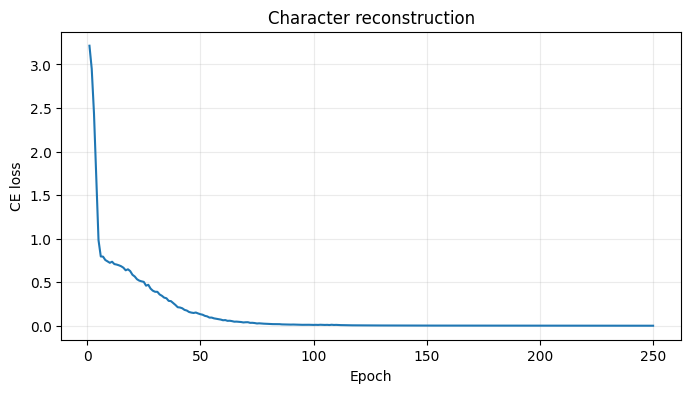

In [6]:
optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
history=[]
for epoch in range(EPOCHS):
    model.train(); totals=defaultdict(float); steps=0
    for one_hot,target_ids,_ in loader:
        one_hot=one_hot.to(DEVICE); target_ids=target_ids.to(DEVICE)
        optimizer.zero_grad()
        logits,mu,_=model(one_hot)
        rec=F.cross_entropy(logits.reshape(-1,VOCAB_SIZE),target_ids.reshape(-1))
        rz=riesz_energy(mu)
        loss=rec+BETA_RIESZ*rz
        loss.backward(); optimizer.step()
        totals['loss']+=float(loss.detach().cpu()); totals['rec']+=float(rec.detach().cpu()); totals['riesz']+=float(rz.detach().cpu()); steps+=1
    row={'epoch':epoch+1,'loss':totals['loss']/steps,'reconstruction':totals['rec']/steps,'riesz':totals['riesz']/steps}; history.append(row)
    if epoch==0 or (epoch+1)%25==0:
        print(f"Epoch {epoch+1:3d} | loss={row['loss']:.4f} | rec={row['reconstruction']:.4f} | riesz={row['riesz']:.4f}")
history=pd.DataFrame(history)
display(history.tail())
plt.figure(figsize=(8,4)); plt.plot(history['epoch'],history['reconstruction']); plt.xlabel('Epoch'); plt.ylabel('CE loss'); plt.title('Character reconstruction'); plt.grid(alpha=.25); plt.show()


## 5. Encode and reconstruct words


In [7]:
model.eval(); word_latents={}
with torch.no_grad():
    for word in words:
        ids=encode_word_indices(word); x=torch.tensor(indices_to_one_hot(ids),dtype=torch.float32,device=DEVICE).unsqueeze(0)
        word_latents[word]=model.encode_direction(x)[0].cpu().numpy()

def decode_latent_word(z):
    zt=torch.tensor(z,dtype=torch.float32,device=DEVICE).unsqueeze(0)
    with torch.no_grad(): logits=model.decode_logits(zt)[0]
    return decode_indices(logits.argmax(dim=-1).cpu().numpy())

rows=[]
for word in ["cat","cats","tiger","lion","category","walk","walked","walking","happy","unhappy"]:
    if word in word_latents:
        recon=decode_latent_word(word_latents[word]); rows.append({'input':word,'reconstruction':recon,'exact':recon==word})
display(pd.DataFrame(rows))


,input,reconstruction,exact
0,cat,cat,True
1,cats,cats,True
2,tiger,tiger,True
3,lion,lion,True
4,category,category,True
5,walk,walk,True
6,walked,walked,True
7,walking,walking,True
8,happy,happy,True
9,unhappy,unhappy,True


## 6. Sphere geometry


In [8]:
EPS=1e-10

def normalize_vector(v):
    v=np.asarray(v,dtype=np.float64); n=np.linalg.norm(v)
    if n<EPS: raise ValueError("Near-zero vector")
    return v/n

def spherical_distance(x,y):
    x=normalize_vector(x); y=normalize_vector(y)
    return np.arccos(np.clip(np.dot(x,y),-1.0,1.0))

def log_map(x,y):
    x=normalize_vector(x); y=normalize_vector(y); c=np.clip(np.dot(x,y),-1.0,1.0); a=np.arccos(c)
    if a<EPS: return np.zeros_like(x)
    return a*normalize_vector(y-c*x)

def exp_map(x,v):
    x=normalize_vector(x); v=np.asarray(v,dtype=np.float64); v=v-np.dot(v,x)*x; n=np.linalg.norm(v)
    if n<EPS: return x.copy()
    return normalize_vector(np.cos(n)*x+np.sin(n)*v/n)

def parallel_transport(v,x,y):
    x=normalize_vector(x); y=normalize_vector(y); v=np.asarray(v,dtype=np.float64); v=v-np.dot(v,x)*x
    den=1.0+np.dot(x,y)
    if abs(den)<1e-8: raise ValueError("Near-antipodal transport")
    out=v-(np.dot(v,y)/den)*(x+y)
    return out-np.dot(out,y)*y

def relation_guided_spherical_motion(start_point,relation_vector,distance_scale=1.5,n_steps=81):
    start_point=normalize_vector(start_point); relation_vector=np.asarray(relation_vector,dtype=np.float64)
    relation_vector=relation_vector-np.dot(relation_vector,start_point)*start_point
    rn=np.linalg.norm(relation_vector)
    if rn<EPS: raise ValueError("Near-zero relation")
    u0=relation_vector/rn; ts=np.linspace(0,1,n_steps); pts=[]; vecs=[]
    for t in ts:
        p=exp_map(start_point,t*distance_scale*relation_vector)
        ut=normalize_vector(parallel_transport(u0,start_point,p))
        pts.append(p); vecs.append(rn*ut)
    return {'t_values':ts,'path_points':np.vstack(pts),'path_vectors':np.vstack(vecs),'relation_norm':rn,'distance_scale':distance_scale}


## 7. Nearest words: spelling structure vs semantics


In [9]:
def nearest_words(query_word,k=8):
    q=word_latents[query_word]; rows=[]
    for word,z in word_latents.items():
        if word==query_word: continue
        rows.append({'word':word,'distance_deg':float(np.degrees(spherical_distance(q,z)))})
    return pd.DataFrame(rows).sort_values('distance_deg').head(k).reset_index(drop=True)

for query in ["cat","tiger","walk","happy"]:
    print("\nQuery:",query); display(nearest_words(query,8))



Query: cat


,word,distance_deg
0,car,23.497148
1,cats,26.988648
2,cow,28.610319
3,cater,32.731242
4,cars,35.567585
5,call,37.931309
6,cows,41.765545
7,walk,43.757524



Query: tiger


,word,distance_deg
0,tigers,23.582836
1,tree,38.643426
2,rivers,39.064617
3,river,40.654040
4,trees,43.256594
5,pig,44.229956
6,rome,46.576948
7,train,49.661814



Query: walk


,word,distance_deg
0,talk,25.413238
1,call,33.988864
2,walking,35.146742
3,work,36.853910
4,walked,39.441595
5,talked,42.937672
6,wolf,43.650034
7,cat,43.757524



Query: happy


,word,distance_deg
0,paris,42.197429
1,feline,47.105343
2,dance,47.961446
3,helped,48.217963
4,danced,49.162976
5,capital,57.052175
6,help,58.027636
7,helping,61.546038


## 8. Direct spelling-vs-semantics comparison

特别比较：

- `tiger` vs `lion`：语义近但拼写差异大
- `cat` vs `category`：拼写前缀相似但语义关系不同

如果 character VAE 偏向 orthography，通常会更容易让字符相似词靠近。


In [10]:
PAIRS=[
    ("tiger","lion","semantic similarity"),
    ("cat","category","orthographic similarity"),
    ("walk","walked","morphology"),
    ("walk","walking","morphology"),
    ("dog","dogs","morphology"),
    ("happy","unhappy","prefix morphology"),
    ("rome","italy","semantic relation"),
    ("paris","france","semantic relation"),
]
rows=[]
for a,b,label in PAIRS:
    if a in word_latents and b in word_latents:
        rows.append({'word_1':a,'word_2':b,'type':label,'angle_deg':float(np.degrees(spherical_distance(word_latents[a],word_latents[b])))})
display(pd.DataFrame(rows).sort_values('angle_deg'))


,word_1,word_2,type,angle_deg
4,dog,dogs,morphology,27.101227
3,walk,walking,morphology,35.146742
2,walk,walked,morphology,39.441595
1,cat,category,orthographic similarity,48.025444
0,tiger,lion,semantic similarity,72.648533
5,happy,unhappy,prefix morphology,82.427792
7,paris,france,semantic relation,96.630049
6,rome,italy,semantic relation,119.938638


## 9. Morphological relations + relation-guided motion


In [11]:
MORPH_RELATIONS=[
    ("cat","cats"),("dog","dogs"),("lion","lions"),
    ("walk","walked"),("play","played"),("talk","talked"),
    ("walk","walking"),("play","playing"),
]
ANGLE_SCALES=[0.50,1.00,1.50]
rows=[]
for a,b in MORPH_RELATIONS:
    if a not in word_latents or b not in word_latents: continue
    rel=log_map(word_latents[a],word_latents[b]); base_deg=float(np.degrees(np.linalg.norm(rel)))
    for scale in ANGLE_SCALES:
        motion=relation_guided_spherical_motion(word_latents[a],rel,scale,81); endpoint=motion['path_points'][-1]
        rows.append({'relation':f'{a}→{b}','scale':scale,'original_angle_deg':base_deg,'travelled_angle_deg':scale*base_deg,'decoded_endpoint':decode_latent_word(endpoint)})
display(pd.DataFrame(rows))


,relation,scale,original_angle_deg,travelled_angle_deg,decoded_endpoint
0,cat→cats,0.5,26.988648,13.494324,cat
1,cat→cats,1.0,26.988648,26.988648,cats
2,cat→cats,1.5,26.988648,40.482972,catse
3,dog→dogs,0.5,27.101227,13.550613,dog
4,dog→dogs,1.0,27.101227,27.101227,dogs
5,dog→dogs,1.5,27.101227,40.651840,dogs
6,lion→lions,0.5,32.793022,16.396511,lion
7,lion→lions,1.0,32.793022,32.793022,lions
8,lion→lions,1.5,32.793022,49.189533,lions
9,walk→walked,0.5,39.441595,19.720797,walke


## 10. 3D local sphere visualization


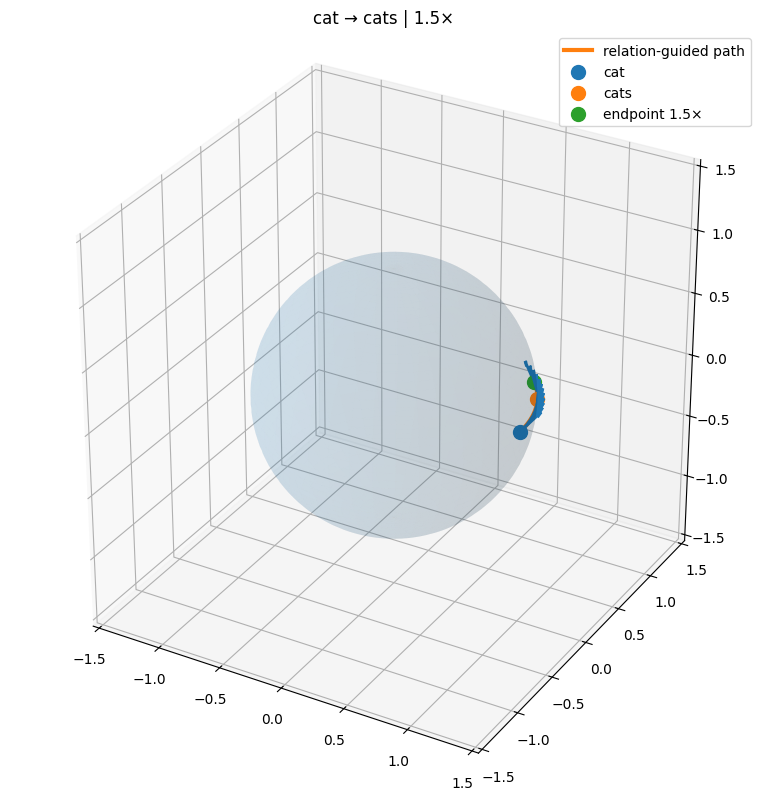

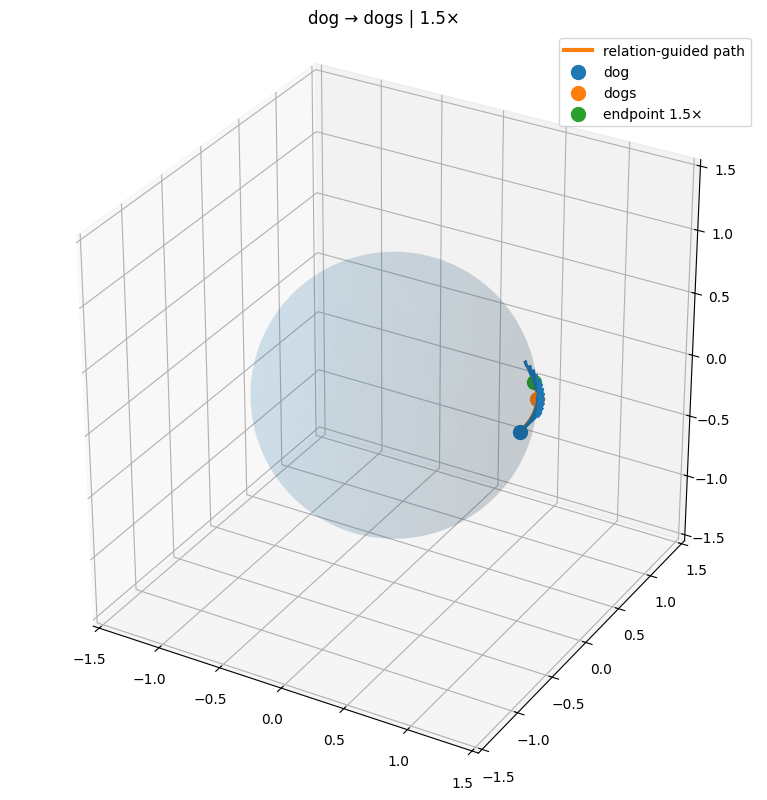

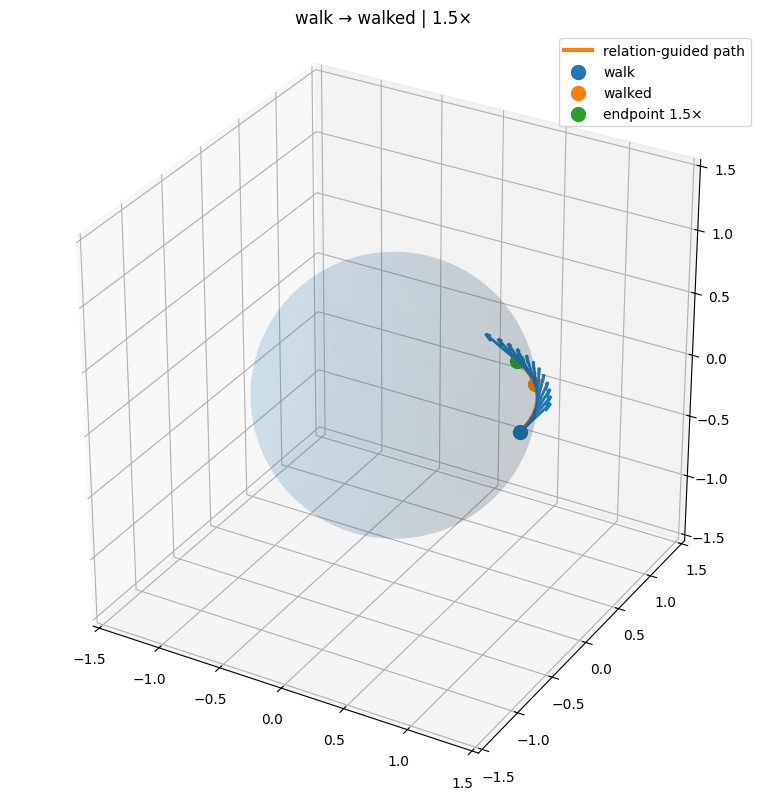

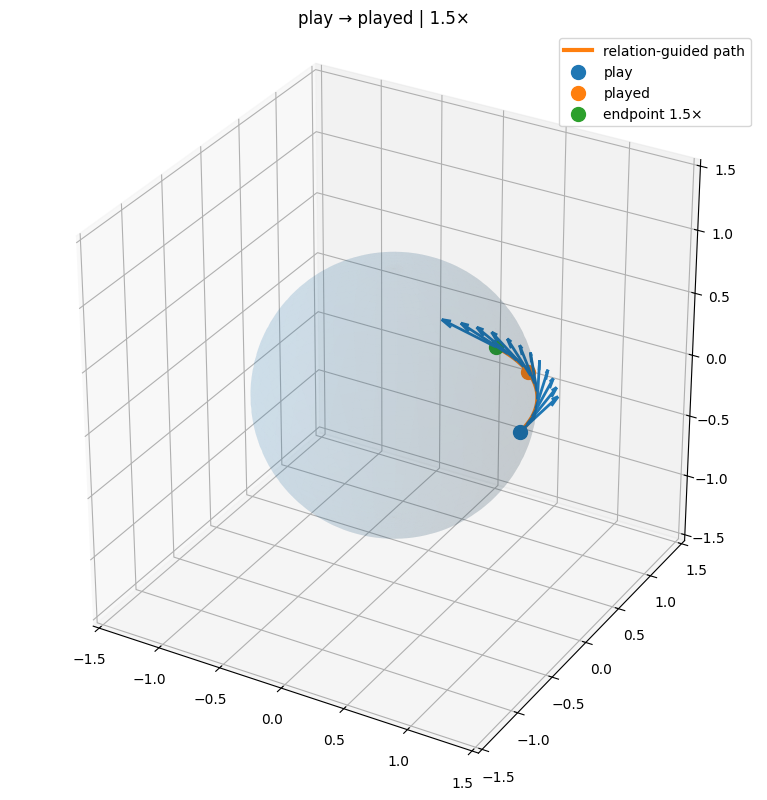

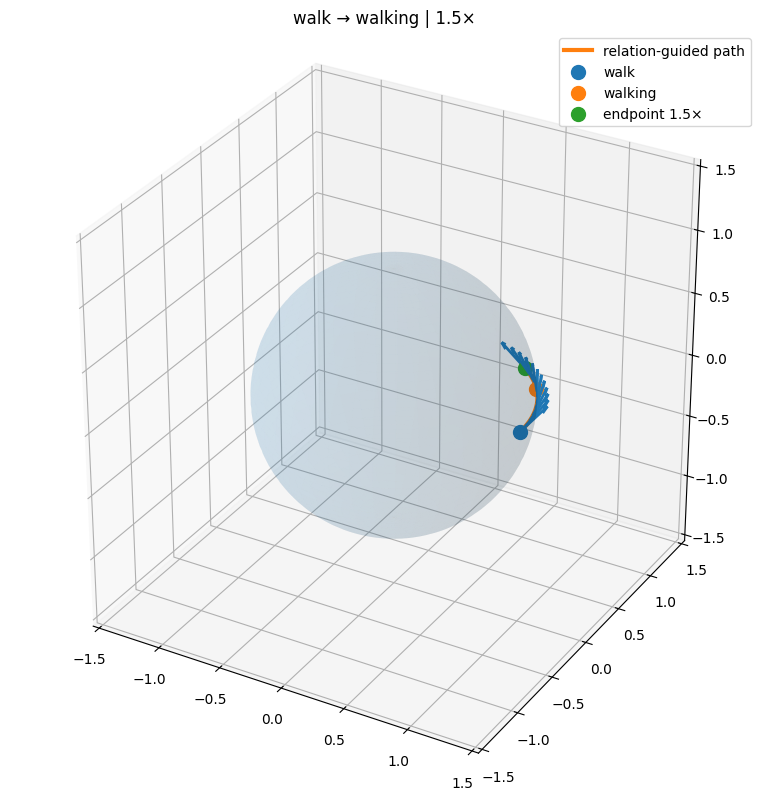

In [12]:
def build_relation_basis(start_point,relation_vector):
    e1=normalize_vector(start_point); e2=normalize_vector(relation_vector-np.dot(relation_vector,e1)*e1)
    candidate=np.zeros_like(e1)
    for idx in np.argsort(np.abs(e1)+np.abs(e2)):
        candidate[:]=0; candidate[idx]=1
        e3=candidate-np.dot(candidate,e1)*e1-np.dot(candidate,e2)*e2
        if np.linalg.norm(e3)>EPS: break
    e3=normalize_vector(e3); return np.stack([e1,e2,e3],axis=1)

def draw_unit_sphere(ax):
    u=np.linspace(0,2*np.pi,80); v=np.linspace(0,np.pi,50)
    x=np.outer(np.cos(u),np.sin(v)); y=np.outer(np.sin(u),np.sin(v)); z=np.outer(np.ones_like(u),np.cos(v))
    ax.plot_surface(x,y,z,alpha=.10,linewidth=0)

def plot_word_relation_motion(source_word,target_word,distance_scale=1.5,n_arrows=12):
    source=word_latents[source_word]; target=word_latents[target_word]; rel=log_map(source,target)
    motion=relation_guided_spherical_motion(source,rel,distance_scale,81); basis=build_relation_basis(source,rel)
    path=motion['path_points']@basis; vecs=motion['path_vectors']@basis; s=source@basis; t=target@basis
    sel=np.linspace(0,len(path)-1,n_arrows,dtype=int)
    fig=plt.figure(figsize=(10,8)); ax=fig.add_subplot(111,projection='3d'); draw_unit_sphere(ax)
    ax.plot(path[:,0],path[:,1],path[:,2],linewidth=3,label='relation-guided path')
    for i in sel:
        p=path[i]; v=vecs[i]
        ax.quiver(p[0],p[1],p[2],.65*v[0],.65*v[1],.65*v[2],arrow_length_ratio=.18,linewidth=2)
    ax.scatter(s[0],s[1],s[2],s=100,label=source_word); ax.scatter(t[0],t[1],t[2],s=100,label=target_word)
    e=path[-1]; ax.scatter(e[0],e[1],e[2],s=100,label=f'endpoint {distance_scale}×')
    ax.set_xlim(-1.55,1.55); ax.set_ylim(-1.55,1.55); ax.set_zlim(-1.55,1.55); ax.set_box_aspect((1,1,1))
    ax.set_title(f'{source_word} → {target_word} | {distance_scale}×'); ax.legend(); plt.tight_layout(); plt.show()

for a,b in [("cat","cats"),("dog","dogs"),("walk","walked"),("play","played"),("walk","walking")]:
    plot_word_relation_motion(a,b,1.5,12)
